<a href="https://colab.research.google.com/github/CRojas-2/CRojas-2/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [104]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [105]:
# cargar archivos
plans = pd.read_csv('plans.csv')
users = pd.read_csv('users_latam.csv')#completa el código
usage = pd.read_csv('usage.csv')#completa el código

In [106]:
# mostrar las primeras 5 filas de plan
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [107]:
# mostrar las primeras 5 filas de users

users.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [108]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [109]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [110]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [111]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [112]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [113]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [114]:
# cantidad de nulos para usage
print(usage.isna().sum())# Cantidad de valores nulos
print(usage.isna().mean())# Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Users:
- city: 469 nulos (11.72%) → Imputar con moda para mantener segmentación geográfica. Tener presente el dato por si genera sesgo.
- Churn:
- churn_date: 3534 nulos (88.35%) → Ignorar columna (no hace parte del análisis)
- Usage:
- date: 50 nulos (0.12%) → Eliminar filas para preservar trazabilidad temporal
- duration: 22076 nulos (55.19%) → Dejar como NaN (datos de mensajes, no tienen duración)
- length: 17896 nulos (44.74%) → Dejar como NaN (datos de llamadas, no tienen longitud)

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [115]:
# explorar columnas numéricas de users
users[["user_id","age"]].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` se ven datos coherenetes de un conteo ascendente desde 10000 hasta 13999 correspondientes a los 4000 datos existentes. la media es consisente e igual a la mediana, no hay nulos.
- La columna `age` tiene un valor extremo mínimo de "-999", su valor máximo es coherente así como el resto de cuantiles. Puede existir otro valor inválido como "0" o "-1" para tener en cuenta en la limpieza.

In [116]:
# explorar columnas numéricas de usage
usage[["id","user_id","duration","length"]].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` corresponden al contador de la tabla y la llave de usuario respectivamente. Toda su estadistica descriptiva es coherente y nos indica que son valores consecutivos sin nulos ni saltos numéricos. Incluso se observa una distribución homogenea de usuarios mostrando que cada cliente tiene aproxiamdamente la misma cantidad de interacciones de uso del plan.
- Las columnas 'duration' y 'length' tienen valores mínimos "0" que corresponden a los datos donde no hay informaciónde dicha columna como se explicó anterirormente. Se debe verificar si la unidad de cada valor es 'minutos' para la columna 'duration' y 'caracteres' para la columna 'length'. En amabas columnas se puede observar que hasta el cuantil 75 los datos son homogeneos y valores pequeños, pero los máximos ya se alejan muchísimo pudiendo ser un indicador de outliers que se analizarán más adelante. Asimismo se puede hallar el valor mínimo real de cada columna (mayor que cero).

In [117]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595



- La columna `city` Aquí observamos nuevamente que hay datos nulos, observamos que hay 7 ciudades en total, con Bogotá siendo la más frecuente con 808 datos. Tener en cuenta que al rellenar valores faltantes con la moda, su frecuencia aumenta. Por esto se debe tener en cuenta el impacto que pueda tener en nuestro análisis.
- La columna `plan` Aquí confirmamos que no hay datos faltantes, únicamente 2 categorias de plan (Básico, Premium), siendo el más contratado el plan 'Básico' con 2595 clientes.


In [118]:
# explorar columna categórica de usage
usage['type'].describe()

,type
count,40000
unique,2
top,text
freq,22092



- La columna `type` no presenta valores faltantes, solo tiene dos valores (call, text) y el tipo de uso más frecuente es 'text' con 22092 registros



---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  


Columnas con valores inválidos o sentinels identificados

age: se detecta el valor inválido -999, y potencialmente 0 o -1, los cuales podrían representar datos faltantes o errores de captura.
duration y length: presentan valores 0 que aparentemente representan ausencia de información o actividad. Además, sus valores máximos sugieren posibles outliers.

city: contiene valores nulos.

id, user_id, plan y type: no presentan inconsistencias, nulos ni anomalías relevantes.

Acciones recomendadas

age: reemplazar valores inválidos por NaN y realizar imputación preferiblemente con la mediana o segmentada por grupos relevantes.

duration y length: validar el significado de los 0; conservarlos si representan “no aplica” o convertirlos a NaN si corresponden a datos faltantes. Posteriormente analizar y tratar outliers.

city: Para nuestro análisis no es una columna necesaria. Para análisis por región se puede imputar con la moda o crear una categoría "Unknown" para evitar sesgos en la distribución.

Mantener sin transformación las columnas estructurales y categóricas consistentes (id, user_id, plan, type).

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [119]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"],errors='coerce') # si hay errores no falla


In [120]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce') # si hay errores no falla

In [121]:

# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()# Datos unicos de año


array([2022, 2026, 2023, 2024], dtype=int32)

En `reg_date`, tenemos 4 valores únicos (2022, 2023, 2024, 2026)

In [122]:
# Revisar los años presentes en `date` de usage

usage['date'].dropna().dt.year.unique()

array([2024], dtype=int32)

En `date`, eliminamos las filas que no tienen fecha y extraemos los años que tienen registro. Como solo hay registros del 2024, basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Diagnóstico**

    Columna usage['date']: Fecha de uso del plan. Los registros corresponden exclusivamente al año 2024, el cual es consistente con el marco temporal del análisis. Se limita el análisis a este año únicamente.

    Columna users['reg_date']: Fecha de registro del usuario. Se detecta presencia de datos en los años 2022, 2023, 2024 y 2026. El año 2026 representa una fecha futura o imposible si el análisis se sitúa en 2024. usuarios registrados en años anteriores pueden haber tenido actividad en 2024 por lo cual no se descartan.
    
**Acción recomendada**

    Registros del año 2026 en users['reg_date'], Fechas de usuarios futuros, imposibles de tener actividad en 2024. Se reemplazan datos de 2026 por NA.
    
    Registros de 2022 y 2023 en users['reg_date'], Fechas de registro de usuario válidas. Indican usuarios antiguos que pueden haber generado actividad en el 2024. Se mantienen estos datos para el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [123]:


# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = pd.to_numeric(users['age'].replace([-999,0,-1], age_mediana)) #convertir a tipo número y rellenar inválidos con mediana
# Verificar cambios
users['age'].describe()


,age
count,4000.000000
mean,48.122250
std,17.690408
min,18.000000
25%,33.000000
50%,47.000000
75%,63.000000
max,79.000000


In [124]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?',pd.NA)

# Verificar cambios
users['city'].value_counts()

,count
city,
Bogotá,808
CDMX,730
Medellín,616
GDL,450
Cali,424
MTY,407


In [125]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT #se asigna 'Not a Time' a las fechas donde el año es 2026
# Verificar cambios
users['reg_date'].dt.year.value_counts()

,count
reg_date,
2024.0,1330
2023.0,1316
2022.0,1314


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [126]:
# Verificación MAR en usage (Missing At Random) para duration y length
usage[['type','duration','length']].head(10)

,type,duration,length
0,call,0.09,NaN
1,text,NaN,39.0
2,text,NaN,36.0
3,call,1.53,NaN
4,call,4.84,NaN
5,call,4.68,NaN
6,call,3.27,NaN
7,call,4.81,NaN
8,text,NaN,44.0
9,text,NaN,70.0


In [127]:
#Se verifica la dsitribucion de datos de cada columna
usage[['duration','length']].describe()

,duration,length
count,17924.000000,22104.000000
mean,5.202237,52.127398
std,6.842701,56.611183
min,0.000000,0.000000
25%,1.437500,37.000000
50%,3.500000,50.000000
75%,6.990000,64.000000
max,120.000000,1490.000000


Como se había propuesto más adelante 'duration' (17924 registros) y 'length' (22104 registros) son valores que dependen de 'type'. Las llamadas 'call' tienen duración 'duration' pero no longitud 'length' y viceversa con los mensajes 'text' que tienen longitud 'length' pero no duración 'duration'. Por lo tanto los nulos se dejan tal y como están sin eliminar ningún dato. Tener en cuenta los valores extremos máximos como posibles outliers.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [128]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',           # cuenta cant mensajes por usuario
    'is_call': 'sum',           # cuenta cant llamadas por usuario
    'duration': 'sum'           # suma los minutos de las llamadas
}).reset_index() # se reinicia el indice

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [129]:
# Renombrar columnas
usage_agg.columns = ['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [130]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(usage_agg, users, on=['user_id'],how='inner')
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [131]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,age,reg_date
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000,3959
mean,11999.729432,5.524381,4.478120,23.317054,48.124531,2023-07-03 23:11:34.436427776
min,10000.000000,0.000000,0.000000,0.000000,18.000000,2022-01-01 00:00:00
25%,10999.500000,4.000000,3.000000,11.120000,33.000000,2022-10-02 18:38:37.179294720
50%,12000.000000,5.000000,4.000000,19.780000,47.000000,2023-07-04 13:17:14.358589696
75%,12999.500000,7.000000,6.000000,31.415000,63.000000,2024-04-03 05:38:39.879970048
max,13999.000000,17.000000,15.000000,155.690000,79.000000,2024-12-31 00:00:00
std,1154.898108,2.358416,2.144238,18.168095,17.692032,NaN


In [132]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100


,proportion
plan,
Basico,64.866217
Premium,35.133783


El plan Básico tiene un 84.62% más usuarios que el plan Premium, Si se busca migrar usuarios a la categoría con mayor rentabilidad, hay que analizar los factores que nos pueden ayudar más adelante.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

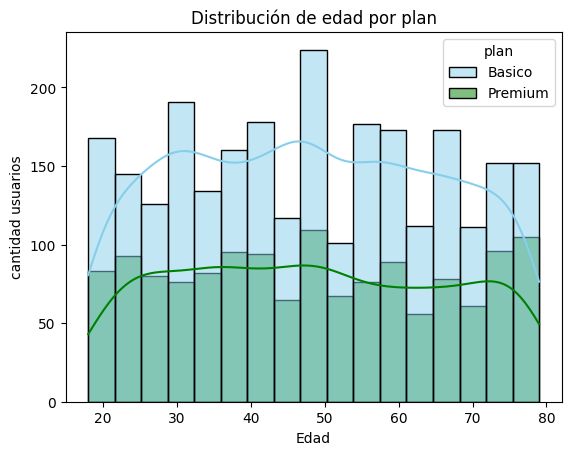

In [133]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan',palette=['skyblue','green'],kde=True)
plt.xlabel('Edad')
plt.ylabel('cantidad usuarios')
plt.title('Distribución de edad por plan')
plt.show()


**Insights:**

    - Al observar la distribución, el comportamiento de ambos segmentos (Básico y Premium) es notablemente plano y uniforme a lo largo de todas las edades (desde los 18 hasta los 79 años). No existen picos pronunciados que vinculen la edad con la preferencia de un plan. Sin embargo, hay dos observaciones importantes:

    - En prácticamente todos los rangos de edad, la cantidad de usuarios en el plan Básico duplica (o supera por un margen amplio) a los usuarios del plan Premium. Por ejemplo, en el pico de usuarios de los 45-50 años, mientras el plan Básico supera los 220 usuarios, el Premium apenas roza los 110.

    - La disposición a pagar por el plan Premium no está madurando con la edad. Se podría asumir teóricamente que a mayor edad (mayor estabilidad financiera), la conversión a Premium aumentaría, pero la gráfica demuestra que un usuario de 60 o 70 años tiene la misma probabilidad de quedarse en el plan Básico que un joven de 25 años.

    - Hay un pico de usuarios entre los 45 y 50 años, que igualmente es homógeneo en su distribución por plan.

**Implicación Estratégica**

    - El cuello de botella para adquirir el plan Premium no es un factor demográfico (edad), sino un factor de propuesta de valor o barrera de precio. El negocio está logrando atraer volumen en el plan Básico de manera homogénea, pero la estrategia de conversión de plan Básico a Premium está estancada bajo el mismo patrón en todas las edades.

**Acciones Recomendadas**

    - Rediseñar la Estrategia de Beneficios: Dado que los adultos mayores y los jóvenes se comportan igual, no segmentar campañas Premium por edad. En su lugar, investigar qué características del plan Premium no están siendo atractivas o justificables frente al costo para el usuario promedio y mejorar la estructura del plan.

    Lanzar Campañas de Conversión basadas en Comportamiento y no en Demografía: En vez de centrar la estrategía en clientes de cierta edad, se deben identificar a los usuarios del plan Básico con alta frecuencia de uso o consumo de datos para ofrecerles pruebas gratuitas del plan Premium y así lograr una fidelización con mayor retorno.

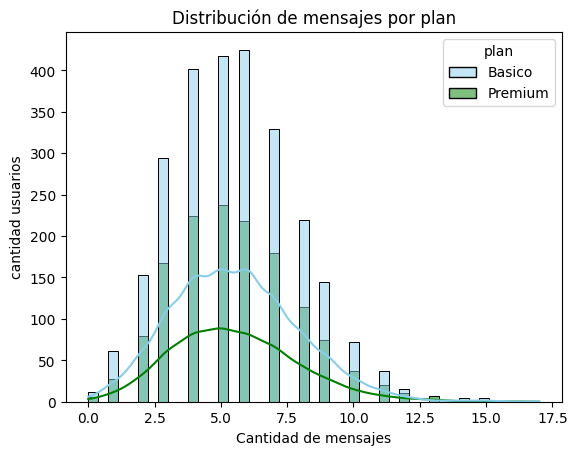

In [134]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile, x='cant_mensajes', hue='plan',palette=['skyblue','green'],kde=True)
plt.xlabel('Cantidad de mensajes')
plt.ylabel('cantidad usuarios')
plt.title('Distribución de mensajes por plan')
plt.show()



**Insights**

  
    - El comportamiento de uso del servicio de mensajería es prácticamente idéntico entre los usuarios del plan Básico y del plan Premium. Ambas curvas de distribución comparten la misma forma, el mismo sesgo y el mismo comportamiento operativo.

    - Moda y Promedio Idénticos: El pico de consumo para ambos grupos se concentra exactamente en el mismo punto entre 4 y 6 mensajes. Un usuario Premium no envía de manera masiva más mensajes que un usuario Básico.

    - Comportamiento similar por tipo de plan y sesgo: Los usuarios Premium se comportan como usuarios Básicos. No existe un segmento de "usuarios pesados"  exclusivo en el plan Premium que justifique un consumo significativamente mayor. Además, hay un sesgo hacia la derecha de unos pocos usuarios de ambos planes que utilizan el servicio más del promedio pero no representan una cantidad considerable.

    - Indicios de limite de mensajes: Nadie, independientemente de su plan, supera los 15 o 17 mensajes.

**Implicación Estratégica**

    - La mensajería no es un factor diferenciador de valor que justifique la separación de los planes. Al tener el mismo comportamiento de consumo, se presentan dos riesgos u oportunidades latentes:

    - Riesgo de Downgrade: Los usuarios Premium podrían darse cuenta eventualmente de que pagan más por un límite o un beneficio de mensajería que realmente no necesitan ni consumen, lo que podría incentivar la migración hacia el plan Básico.

    - Estructura de Costos Eficiente: Por el lado positivo, los usuarios Premium no representan un costo de infraestructura u operación mayor en el área de mensajería que los usuarios del plan Básico, lo que genera un margen de ganancia mayor  en este apartado específico.

**Acciones Recomendadas**

    - Si se busca diseñar un mejor plan a la vez que aumente la satisfacción del cliente, dado que la cantidad de mensajes no escala, el plan Premium debería diferenciarse mediante otros atributos de valor (velocidad de upload/download, aplicaciones, almacenamiento en la nube o seguridad avanzada) en lugar de apostar al volumen de mensajes. También podría evaluarse una reducción del límite de mensajes a 20, redistribuyendo ese porcentaje de capacidad hacia datos de navegación, ya que este representa un diferencial de mayor valor entre ambos tipos de plan.


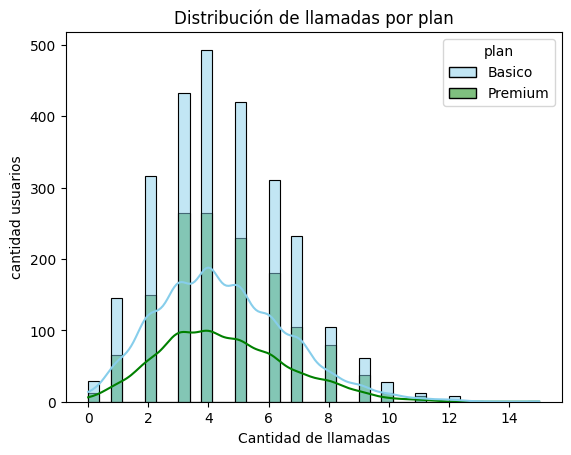

In [135]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan',palette=['skyblue','green'],kde=True)
plt.xlabel('Cantidad de llamadas')
plt.ylabel('cantidad usuarios')
plt.title('Distribución de llamadas por plan')
plt.show()


**Insights**

    -  Los hábitos de uso son idénticos en ambos planes: la mayoría de los clientes realiza entre 3 y 5 llamadas mensuales, y prácticamente nadie supera las 10 (con algunos casos aislados de 12 a 15 llamadas). Esto demuestra que el volumen de llamadas no está funcionando como un beneficio exclusivo que realmente distinga al plan Premium del Básico.

**Implicación Estratégica**

    - Dado que el cliente Premium no consume más llamadas por iniciativa propia, el número de llamadas ya no puede ser el argumento de venta ni la razón para pagar más. Una vez más todo indica que el diferencial puede estar en los datos de navegación.

    - Hay gran margen de ganancia al ser un servicio sub utilizado pero no contribuye a la satisfacción del cliente.
    
**Acciones Recomendadas**

    - Redefinir el valor Premium: Cambiar el foco de la oferta hacia la calidad y la exclusividad en lugar de la cantidad (por ejemplo, ofrecer prioridad de red, herramientas de IA como transcripción de llamadas, o roaming incluido).

    - Justificar el costo para cuidar la satisfacción: Proteger la base de clientes Premium vinculando el precio del plan a beneficios tangibles que no dependan del volumen, tales como seguridad avanzada o soporte técnico preferencial. También se puede validar si un aumento en los datos de navegación influirían en la satisfacción del cliente

    - Validar métricas con urgencia: Cruzar este análisis con la duración en minutos de las llamadas. Si los minutos totales consumidos también resultan ser idénticos entre ambos planes, la reestructuración de la oferta comercial debe ser inmediata ya que no hay valor añadido por los minutos extra del plan Premium

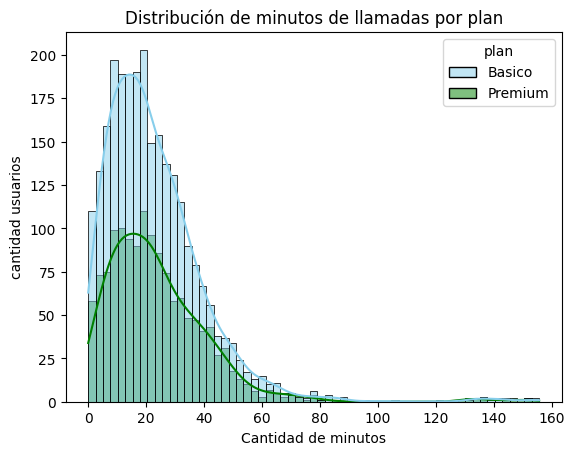

In [136]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan',palette=['skyblue','green'],kde=True)
plt.xlabel('Cantidad de minutos')
plt.ylabel('cantidad usuarios')
plt.title('Distribución de minutos de llamadas por plan')
plt.show()


**Insights**

    - El patrón de uso se es idéntico entre ambos tipos de plan la gran mayoría de los clientes de ambos plan. Muestra un uso moderado-bajo (entre 10 y 25 minutos totales de conversación al mes), con poco casos aislados que superan los 100 minutos mensuales.

    - El gráfico de Distribución de minutos que mientras la curva de consumo natural de minutos cae a cero cerca de los 100 minutos, aparece un grupo aislado de usuarios con valores extremos de hasta 160 minutos mensuales. Este comportamiento rompe la distribución orgánica y genera sesgo hacías la derecha. Aun así, puede representar datos reales de clientes que hacen uso intensivo del servicio de llamadas.

    - El cliente Premium actual no tiene una necesidad de mayor consumo de voz por iniciativa propia.

**Implicación Estratégica**

    - Al tener un consumo idéntico en minutos y llamadas, los usuarios Premium se encuentran en una zona de "subutilización" del servicio. Si descubren que el plan Básico cubre holgadamente su promedio de 20 minutos y 5 llamadas mensuales, migrarán de plan si no ven otro valor adicional útil más allá de la diferencia de datos.

    - El comportamiento atípico de ciertos clientes que utilizan bastante el servicio pueden abrir una brecha a un nuevo tipo de plan que se centre en esos usuarios que necesitan mas voz que otro tipo de servicio.

**Acciones Recomendadas**

    - Aislar usuarios que registren más de 100 minutos en el mes. Validar si la cantidad de clientes es considerable para definir un plan ideal para ellos priorizando voz sobre datos y mensajes.

    - Dado que el grueso del mercado consume menos de 40 minutos mensuales, el plan Básico actual subre muy bien las necesidades de voz de la mayoría de clientes. Reestructurar ambos planes tratando de que sus caracteristicas sean más diferenciadas y aporte un valor agregado qeu el cliente esté dispuesto a pagar. Por ejemplo, disminuir cantidad de emsnajes y llamadas y trasladar ese valor en aumento de anvegación.

    - Para elevar la satisfacción de los usuarios Premium sin depender de que hablen más minutos, la oferta debe migrar hacia beneficios no medidos por volumen: prioridad de datos en zonas congestionadas, herramientas de valor agregado (como herramientas de IA, almacenamiento en la nube o seguridad móvil) y soporte técnico VIP.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

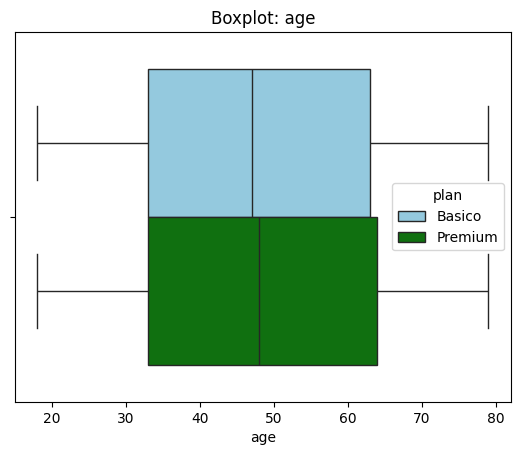

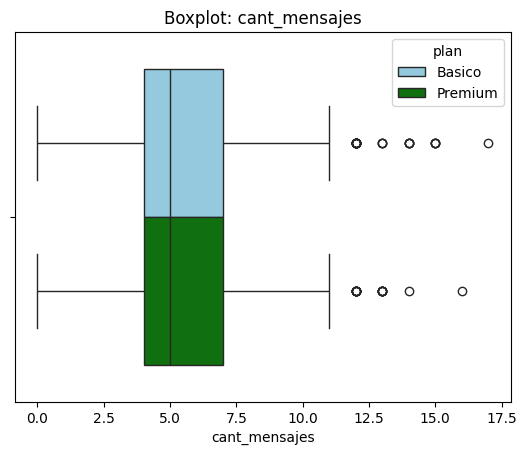

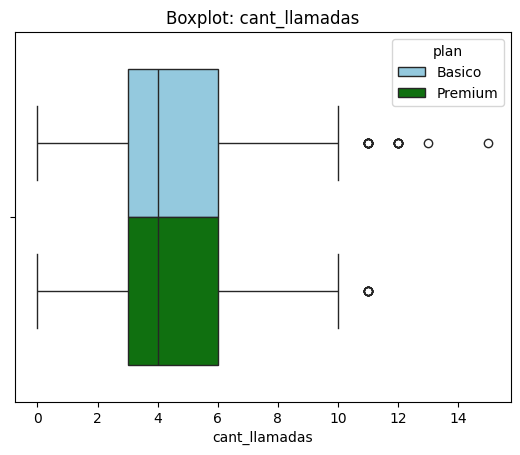

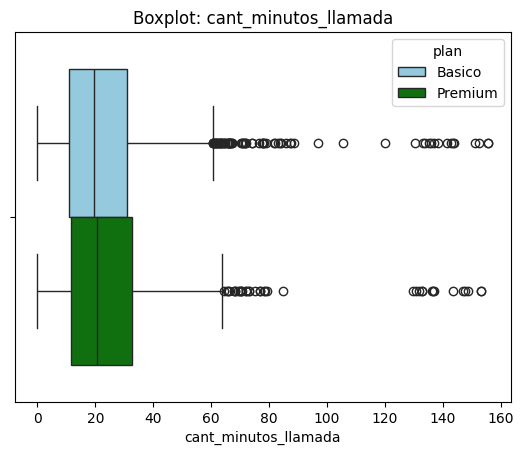

In [137]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, hue='plan', palette=['skyblue','green'])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

In [138]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    # Calcular Q1 (percentil 25) y Q3 (percentil 75)
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    # Calcular el IQR
    IQR = Q3 - Q1

    # Calcular límite superior
    limite_superior = Q3 + 1.5 * IQR

    # Mostrar resultados
    print(f"\n{col}:")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")

    # Contar outliers
    outliers = user_profile[(user_profile[col] > limite_superior)]
    print(f"Cantidad de outliers: {len(outliers)}")


cant_mensajes:
Q1: 4.00
Q3: 7.00
IQR: 3.00
Límite superior: 11.50
Cantidad de outliers: 46

cant_llamadas:
Q1: 3.00
Q3: 6.00
IQR: 3.00
Límite superior: 10.50
Cantidad de outliers: 30

cant_minutos_llamada:
Q1: 11.12
Q3: 31.41
IQR: 20.30
Límite superior: 61.86
Cantidad de outliers: 109


In [139]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


**'Cantidad de mensajes'**

El consumo de mensajería está sumamente estancado; la gran masa de usuarios (sin importar el plan) se concentra en un rango muy bajo de 4 a 6 mensajes mensuales. La distribución decae de forma natural y orgánica hacia los 12 mensajes, y se frena por completo antes de llegar a los 17. A su vez, la media y la mediana son casi iguales lo que indica que los valores están bien distribuidos y por lo tanto los valores extremos corresponden a datos de uso real y legítimo de usuarios más activos del servicio, por lo cual se decide mantener los outliers

**'Cantidad de llamadas'**

Al igual que con los mensajes, el volumen de llamadas presenta un comportamiento espejo entre el plan Básico y Premium. El grueso de la base de clientes realiza entre 3 y 5 llamadas al mes, y la curva cae drásticamente después de las 8 llamadas. Los valores máximos apenas alcanzan las 12 o 15 llamadas en casos muy contados. Los pocos usuarios que realizan entre 10 y 15 llamadas se deben mantener pues repesentan un uso doméstico real aunque mayor al promedio. Su media y median también son muy similiares lo que respalda este análisis.

**'Cantidad de minutos'**

Esta métrica revela el hallazgo más crucial de los datos. Mientras que el 95% de los usuarios tiene una distribución orgánica que decae de forma natural hacia los 70 u 80 minutos mensuales, aparece un grupo aislado y desconectado de la curva principal que registra hasta 160 minutos de consumo. Dentro del contexto de negocio, es completamente entendible que un cliente tenga consumos de estas magnitudes, que de todas maneras no representa un consumo excesivo. Todos los usuarios con consumos mayores a 100 minutos tienen el plan Premium. Su media y  mediana aunque no iguales son similares, dan un indicio de que los valores extremos aunque sean grands y alejados del promedio, siguen representando de fomra fiel el comportamiento real de un usuario.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [140]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where((user_profile['cant_llamadas']<5)
    & (user_profile['cant_mensajes']<5), 'Bajo consumo',np.where((user_profile['cant_llamadas']<10)
    & (user_profile['cant_mensajes']<10), 'Uso medio','Uso alto'))

In [141]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,Uso alto
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Uso alto
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo consumo


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [142]:
# Crear columna grupo_edad

user_profile['grupo_edad'] = np.where(user_profile['age']<30,
                                        'Joven',np.where(user_profile['age']<60,
                                                         'Adulto','Adulto mayor'))


In [143]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,Uso alto,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Uso alto,Adulto mayor
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo consumo,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

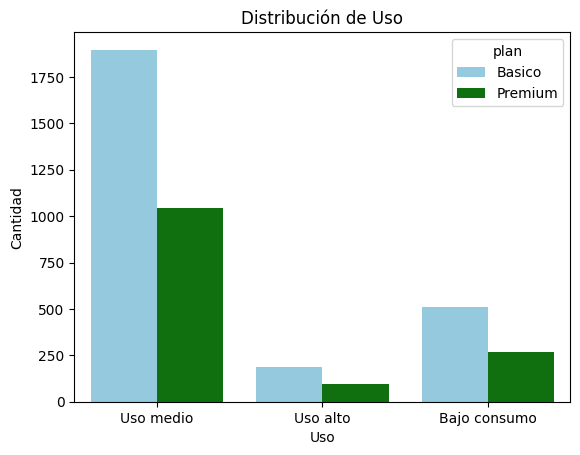

In [144]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x='grupo_uso',hue='plan', palette=['skyblue','green'])
plt.title('Distribución de Uso')
plt.xlabel('Uso')
plt.ylabel('Cantidad')
plt.show()


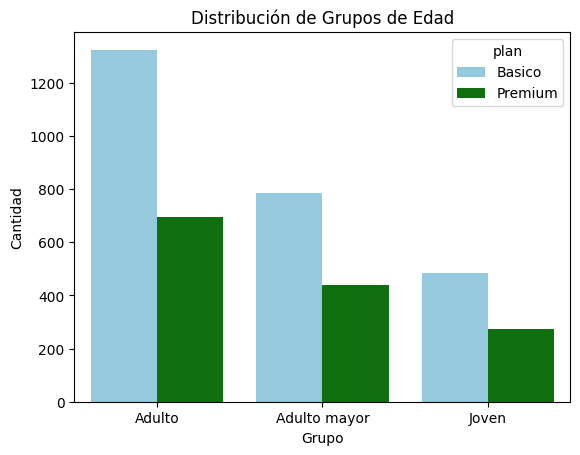

In [145]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad',hue='plan', palette=['skyblue','green'])
plt.title('Distribución de Grupos de Edad')
plt.xlabel('Grupo')
plt.ylabel('Cantidad')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?




### Análisis ejecutivo

**Problemas de calidad en los datos**

El análisis reveló problemas concentrados en variables contextuales de los tres datasets. En 'users' (4.000 registros), la columna 'city' presentó 469 nulos (11,7%), 'churn_date' tuvo 3.534 nulos (88,4%) por lo que fue descartada del análisis, y 'age' contenía el sentinel '-999' junto con posibles valores inválidos '0' y ''-1', todos reemplazados por la mediana. Además, 'reg_date' incluía fechas de regsitro de usuario del año 2026 imposibles dentro del corte de análisis de 2024, que fueron marcadas como nulas. En 'usage' (40.000 registros), se eliminaron 50 filas sin fecha (0,12%) para preservar la trazabilidad temporal, mientras que los 22.076 nulos en 'duration' (55,2%) y los 17.896 en 'length' (44,7%) se mantuvieron intencionalmente al confirmarse como Missing At Random (MAR): cada campo solo aplica a su tipo de registro ('call' o 'text' respectivamente), por lo que su ausencia es estructural y no un error.

**Segmentación de clientes**

Se construyeron dos ejes de segmentación. Por **nivel de uso**: "Bajo consumo" (< 5 llamadas y < 5 mensajes), un grupo numeroso pero no demasiado; "Uso medio" (< 10 llamadas y < 10 mensajes), el grupo más numeroso que representa el consumo mayoritario; y "Alto uso" (≥ 10 en cualquiera), una minoría que realiza usos extremos pero que corresponden a datos reales. Por **edad**: Jóvenes (< 30), Adultos (30–59) y Adultos mayores (≥ 60), siendo los Adultos el segmento dominante con un pico notable entre los 45 y 50 años.

El hallazgo más crítico de la segmentación es que **la edad no explica ni el comportamiento de uso ni la elección de plan**. Las distribuciones de llamadas, mensajes y minutos son prácticamente espejo entre plan Básico y Premium en todos los rangos de edad. Esto significa que el cuello de botella para la conversión al plan Premium no es demográfico, sino de propuesta de valor: el cliente no percibe un beneficio diferencial claro que justifique pagar más o sencillamente por sus necesidades el plan básico es más qeu suficiente.

**Segmentos más valiosos**

El segmento más valioso estratégicamente es el de **"Uso medio en plan Básico"**: es el más numeroso (aproximadamente el 65% de la base), siente el valor del servicio y es el principal candidato a migrar hacia Premium si se construye una oferta más atractiva. Cada punto porcentual de conversión representa un incremento directo en ingresos recurrentes. En paralelo, el segmento de **"Alto uso en plan Premium"** es el cliente de mayor valor al ser quien más utiliza el servicio y por lo tanto ve una necesidad en tenerlo, por lo que es un cliente prioritario en términos de retención, ya que su abandono sería el más costoso de reemplazar.

**Patrones de uso extremo (outliers)**

Los outliers en mensajes (hasta 17), llamadas (hasta 15) son legítimos y representan usuarios más activos dentro de rangos operativamente normales; no requieren tratamiento. El outlier crítico está en los **minutos de llamada**: un grupo aislado de usuarios (todos en plan Premium) registra entre 100 y 160 minutos mensuales, desconectado del 95% de la base que no supera los 70 minutos. Este patrón no es un error: es la señal más clara de una necesidad insatisfecha que el portafolio actual no cubre de forma específica.

Hoy ambos planes generan perfiles de consumo idénticos en las tres variables medidas. Si un usuario Premium consume lo mismo que uno Básico en llamadas, mensajes y minutos, no existe un argumento racional para sostener la diferencia de precio además de la diferencia en datos de navegación. Esto representa un riesgo latente de downgrade masivo si los clientes Premium toman conciencia de ello, y convierte la reestructuración de los planes en una prioridad urgente.


**Recomendaciones**

La diferenciación del plan Premium debe migrar de la *cantidad* hacia la *calidad y exclusividad*: prioridad de red en zonas congestionadas, herramientas de valor agregado como IA integrada, almacenamiento en la nube o seguridad móvil, y soporte técnico VIP. Estos beneficios no dependen del volumen de consumo y son mucho más difíciles de comparar con el plan Básico, lo que reduce el riesgo de downgrade.

Dado que los usuarios no presionan los límites actuales de mensajes ni llamadas, existe capacidad ociosa que puede redistribuirse hacia datos de navegación. Reducir los topes de mensajes y minutos y trasladar ese margen a GB adicionales no aumentaría los costos operativos y mejoraría sustancialmente la propuesta de valor, especialmente en el plan Premium.

La evidencia del cluster de usuarios con más de 100 minutos mensuales justifica la creación de un **tercer plan orientado a voz intensiva**: un "Plan Voz" con minutos elevados o ilimitados, mensajes moderados y menos GB, dirigido a ese perfil específico que hoy está en Premium pero cuyo consumo real no encaja con la estructura del plan.

Finalmente, las campañas de conversión y retención deben diseñarse con base en el **comportamiento de uso**, no en la demografía. La estrategia correcta es identificar usuarios de "Uso medio" en plan Básico que se acerquen a los límites de su plan y ofrecerles migración incentivada o pruebas gratuitas del plan Premium rediseñado. Simultáneamente, los usuarios Premium actuales deben recibir comunicación proactiva que refuerce el valor diferencial del plan antes de que la percepción de paridad con el Básico detone decisiones de downgrade.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`